In [13]:
# Pipeline vs taxonomy: does a pipeline change summary statistics more than biology does?

import json, os, re, sys
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

sys.path.insert(0, os.path.abspath(os.path.join("..", "quality_stats")))
from annotrieve_stats import API, fetch_annotations

os.makedirs("work", exist_ok=True)
os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)

FREEZE = "results/freeze_set.tsv"   # delete to rebuild the freeze set from the live API
RANKS = ["genus", "family", "order", "class", "phylum"]
RELATIONSHIPS = [f"same {r}" for r in RANKS] + ["different phylum"]
PIPELINES = ["RefSeq", "Ensembl"]
x
# every protein-coding gene / mRNA summary in features_statistics (gene_category_stats.coding and
# transcript_type_stats.mRNA): counts, means and per-mRNA ratios. min/max are left out: they are single
# extreme features (often 1 bp exons/CDS), not summaries of the annotation.
LABEL = {
    "coding_gene_count": "coding genes",
    "coding_gene_length": "mean coding gene length (bp)",
    "mrna_count": "mRNAs",
    "mrna_per_gene": "mRNAs per coding gene",
    "mrna_length": "mean mRNA genomic span (bp)",
    "exons_per_mrna": "exons per mRNA",
    "mrna_exon_length": "mean exon length (bp)",
    "mrna_spliced_length": "mean spliced mRNA length (bp)",
    "cds_per_mrna": "CDS segments per mRNA",
    "cds_segment_length": "mean CDS segment length (bp)",
    "cds_concat_length": "mean CDS length per mRNA (bp)",
    "utr_length": "mean UTR length per mRNA (bp)",
}
PANEL = list(LABEL)


def protein_coding_metrics(fs):
    """PANEL from one features_statistics document; NaN when missing or not positive (log2 undefined)."""
    def get(*keys):
        d = fs or {}
        for k in keys:
            d = d.get(k) if isinstance(d, dict) else None
        return np.nan if d is None else float(d)
    gene = ("gene_category_stats", "coding")
    mrna = ("transcript_type_stats", "mRNA")
    n_mrna = get(*mrna, "total_count")
    v = {
        "coding_gene_count": get(*gene, "total_count"),
        "coding_gene_length": get(*gene, "length_stats", "mean"),
        "mrna_count": n_mrna,
        "mrna_per_gene": n_mrna / get(*mrna, "associated_genes", "total_count"),
        "mrna_length": get(*mrna, "length_stats", "mean"),
        "exons_per_mrna": get(*mrna, "exon_stats", "total_count") / n_mrna,
        "mrna_exon_length": get(*mrna, "exon_stats", "length", "mean"),
        "mrna_spliced_length": get(*mrna, "exon_stats", "concatenated_length", "mean"),
        "cds_per_mrna": get(*mrna, "cds_stats", "total_count") / n_mrna,
        "cds_segment_length": get(*mrna, "cds_stats", "length", "mean"),
        "cds_concat_length": get(*mrna, "cds_stats", "concatenated_length", "mean"),
    }
    v["utr_length"] = v["mrna_spliced_length"] - v["cds_concat_length"]
    return {k: x if np.isfinite(x) and x > 0 else np.nan for k, x in v.items()}


In [14]:
# fetch annotreive reference assemblies that have an annotation from ensambl and from refseq and define it as a freeze set
# RefSeq: NCBI RefSeq provider, NCBI Gnomon pipeline (EGAP); EGAPx and propagation pipelines excluded.
# Ensembl: Ensembl Genebuild only (BRAKER / community imports excluded).
# Same assembly = identical accession and version (GCF_X.v == GCA_X.v); latest release per pipeline.
FIELDS = ",".join(["annotation_id", "organism_name", "taxid", "assembly_accession", "taxon_lineage",
                   "source_file_info.database", "source_file_info.provider", "source_file_info.pipeline",
                   "source_file_info.release_date", "features_statistics"])


def cached(path, fetch):
    if not os.path.exists(path):
        with open(path, "w") as fh:
            json.dump(fetch(), fh)
    with open(path) as fh:
        return json.load(fh)


def pipeline_of(sfi):
    name = ((sfi.get("pipeline") or {}).get("name") or "")
    if sfi.get("database") == "Ensembl" and name == "Ensembl Genebuild":
        return "Ensembl"
    if (sfi.get("database") == "RefSeq" and sfi.get("provider") == "NCBI RefSeq"
            and "eukaryotic genome annotation pipeline" in name.lower() and "egapx" not in name.lower()):
        return "RefSeq"
    return None


# The reference filter is applied to RefSeq only: the API's refseq_categories filter misses many Ensembl
# annotations on the GCA twin of a reference GCF; the identical-version match below makes them the same sequence.
records = cached("work/annotations.json", lambda:
    fetch_annotations({"refseq_categories": "reference genome", "db_sources": "RefSeq"}, FIELDS)
    + fetch_annotations({"db_sources": "Ensembl", "pipelines": "Ensembl Genebuild"}, FIELDS))
print(f"{len(records)} annotations (RefSeq on reference genomes + all Ensembl Genebuild)")

ann = pd.DataFrame([{
    "annotation_id": r["annotation_id"], "organism_name": r["organism_name"], "taxid": int(r["taxid"]),
    "assembly_accession": r["assembly_accession"],
    "assembly": re.sub(r"^GC[AF]_", "", r["assembly_accession"]),      # accession.version without prefix
    "pipeline": pipeline_of(r["source_file_info"]),
    "pipeline_name": (r["source_file_info"].get("pipeline") or {}).get("name"),
    "release_date": r["source_file_info"].get("release_date"),
} for r in records])
ann = ann[ann.pipeline.notna()]
latest = ann.sort_values("release_date").drop_duplicates(["assembly", "pipeline"], keep="last")
both = latest.groupby("assembly").pipeline.nunique().loc[lambda s: s == 2].index
freeze_new = latest[latest.assembly.isin(both)].sort_values(["assembly", "pipeline"])

if os.path.exists(FREEZE):
    freeze = pd.read_csv(FREEZE, sep="\t", dtype={"assembly": str})
    print(f"using existing freeze set {FREEZE} ({freeze.freeze_date.iloc[0]}); "
          f"live API now gives {freeze_new.assembly.nunique()} assemblies")
else:
    freeze = freeze_new.assign(freeze_date=date.today().isoformat())
    freeze.to_csv(FREEZE, sep="\t", index=False)
print(f"freeze set: {freeze.assembly.nunique()} assemblies, {freeze.taxid.nunique()} species, {len(freeze)} annotations")
freeze.head()


6414 annotations (RefSeq on reference genomes + all Ensembl Genebuild)
using existing freeze set results/freeze_set.tsv (2026-11-04); live API now gives 416 assemblies
freeze set: 416 assemblies, 416 species, 832 annotations


,annotation_id,organism_name,taxid,assembly_accession,assembly,pipeline,pipeline_name,release_date,freeze_date
0,6c3181ef3c137847d096cbcc754c7192,Xenopus tropicalis,8364,GCA_000004195.4,000004195.4,Ensembl,Ensembl Genebuild,2021-02-01T00:00:00,2026-11-04
1,5111ca1628bbccebc4ce99eb668a9ab0,Xenopus tropicalis,8364,GCF_000004195.4,000004195.4,RefSeq,NCBI Eukaryotic Genome Annotation Pipeline (EGAP),2019-12-06T00:00:00,2026-11-04
2,52042ceba025e20df59b37562320c62e,Myotis lucifugus,59463,GCA_000147115.1,000147115.1,Ensembl,Ensembl Genebuild,2011-06-01T00:00:00,2026-11-04
3,c34bcd3a55dd0027f331e2be7ebf58b8,Myotis lucifugus,59463,GCF_000147115.1,000147115.1,RefSeq,NCBI eukaryotic genome annotation pipeline,2018-01-17T00:00:00,2026-11-04
4,3464abb67f5eaba9f8987f101bac21eb,Pundamilia nyererei,303518,GCA_000239375.1,000239375.1,Ensembl,Ensembl Genebuild,2018-07-01T00:00:00,2026-11-04


In [15]:
# Fetch all the summary statistics for protein coding genes of these annotations (there should be 2 per assembly)
by_id = {r["annotation_id"]: r for r in records}
missing = set(freeze.annotation_id) - set(by_id)
if missing:   # freeze set older than the cache: fetch those records by id
    by_id.update({r["annotation_id"]: r for r in fetch_annotations({"md5_checksums": ",".join(missing)}, FIELDS)})

stats = pd.DataFrame([{"annotation_id": a, **protein_coding_metrics(by_id[a].get("features_statistics"))}
                      for a in freeze.annotation_id])
stats = freeze.merge(stats, on="annotation_id")
assert (stats.groupby("assembly").size() == 2).all()

# genome table: one row per assembly, RefSeq and Ensembl values side by side
wide = pd.concat([stats.pivot(index="assembly", columns="pipeline", values=PANEL).astype(float),
                  stats.pivot(index="assembly", columns="pipeline", values=["annotation_id"])], axis=1)
wide.columns = [f"{p}_{m}" for m, p in wide.columns]
genomes = (stats.drop_duplicates("assembly").set_index("assembly")[["organism_name", "taxid"]]
           .join(wide).reset_index())
# a missing value only removes that assembly from that metric (pairs are filtered per metric below)
na = pd.DataFrame({LABEL[m]: {p: genomes[f"{p}_{m}"].isna().sum() for p in PIPELINES} for m in PANEL}).T
print(f"{len(genomes)} assemblies; missing values per metric:")
print(na[na.sum(axis=1) > 0].to_string() if na.values.any() else "none")
genomes[["organism_name"] + [f"{p}_{m}" for m in PANEL for p in PIPELINES]].describe().T.round(2)


416 assemblies; missing values per metric:
                               RefSeq  Ensembl
mean UTR length per mRNA (bp)       0        3


,count,mean,std,min,25%,50%,75%,max
RefSeq_coding_gene_count,416.0,21539.33,6829.06,9996.00,17067.25,21268.50,23706.50,61810.00
Ensembl_coding_gene_count,416.0,21524.89,7267.88,10105.00,16919.50,20480.00,23351.25,56542.00
RefSeq_coding_gene_length,416.0,31846.14,17773.89,3203.51,18721.64,26191.06,45665.80,101117.55
Ensembl_coding_gene_length,416.0,28580.38,16984.45,2970.44,15879.36,23179.25,42809.20,91725.89
RefSeq_mrna_count,416.0,43095.80,15164.71,11869.00,33425.50,42267.50,51271.25,115701.00
Ensembl_mrna_count,416.0,45651.74,21848.93,14862.00,29584.25,39133.00,59911.50,144376.00
RefSeq_mrna_per_gene,416.0,2.03,0.52,1.03,1.68,1.92,2.37,4.20
Ensembl_mrna_per_gene,416.0,2.08,0.55,1.05,1.64,1.92,2.47,3.62
RefSeq_mrna_length,416.0,44691.32,25630.04,3532.84,25302.24,35822.02,62527.44,151791.42
Ensembl_mrna_length,416.0,35021.19,21386.41,2775.15,18623.51,29041.66,52542.35,119894.00


In [16]:
# compute log2 fold change between ensembl and RefSeq summary metrics of two annotations of the same assemly
# signed log2(RefSeq / Ensembl): > 0 means RefSeq reports the larger value
for m in PANEL:
    genomes[f"pipeline_log2fc_{m}"] = np.log2(genomes[f"RefSeq_{m}"] / genomes[f"Ensembl_{m}"])

within_summary = pd.DataFrame({
    LABEL[m]: {
        "median log2FC (RefSeq/Ensembl)": genomes[f"pipeline_log2fc_{m}"].median(),
        "median |log2FC|": genomes[f"pipeline_log2fc_{m}"].abs().median(),
        "median fold difference": 2 ** genomes[f"pipeline_log2fc_{m}"].abs().median(),
        "fraction RefSeq > Ensembl": (genomes[f"pipeline_log2fc_{m}"].dropna() > 0).mean(),
    } for m in PANEL}).T.round(3)
genomes.to_csv("results/genomes.tsv", sep="\t", index=False)
within_summary


,median log2FC (RefSeq/Ensembl),median |log2FC|,median fold difference,fraction RefSeq > Ensembl
coding genes,0.034,0.081,1.057,0.635
mean coding gene length (bp),0.140,0.155,1.113,0.844
mRNAs,-0.142,0.447,1.363,0.425
mRNAs per coding gene,-0.082,0.377,1.299,0.447
mean mRNA genomic span (bp),0.314,0.314,1.243,0.959
exons per mRNA,0.158,0.182,1.135,0.743
mean exon length (bp),0.364,0.364,1.287,0.945
mean spliced mRNA length (bp),0.474,0.475,1.390,0.962
CDS segments per mRNA,0.120,0.160,1.117,0.673
mean CDS segment length (bp),0.106,0.106,1.076,0.964


In [17]:
# compute log2 fold change between every pair of assemblies comparing summary metrics of RefSeq Annotations.
# Repeat the same of Ensembl.
# signed log2(i / j) for i < j (the order is arbitrary, so the comparisons below use |log2FC|)
n = len(genomes)
I, J = np.triu_indices(n, k=1)
pairs = pd.DataFrame({"i": I, "j": J,
                      "assembly_i": genomes.assembly.values[I], "assembly_j": genomes.assembly.values[J],
                      "organism_i": genomes.organism_name.values[I], "organism_j": genomes.organism_name.values[J]})
for m in PANEL:
    for p in PIPELINES:
        x = np.log2(genomes[f"{p}_{m}"].values)
        pairs[f"{p}_log2fc_{m}"] = x[I] - x[J]
    # reference point for each pair: mean same-assembly pipeline effect of its two genomes
    e = genomes[f"pipeline_log2fc_{m}"].abs().values
    pairs[f"pipeline_effect_{m}"] = (e[I] + e[J]) / 2
print(f"{len(pairs)} assembly pairs")


86320 assembly pairs


In [18]:
# For every assembly couple, also annotate the relationship (same genus, same family,  same order,  same class, same phylum, different phylym)
# rank of each lineage taxid: from /taxons?rank=<rank>
def fetch_rank(rank):
    taxa, offset = [], 0
    while True:
        r = requests.get(f"{API}/taxons", params={"rank": rank, "limit": 1000, "offset": offset}, timeout=120)
        r.raise_for_status()
        page = r.json()
        taxa += [t["taxid"] for t in page["results"]]
        offset += 1000
        if offset >= page["total"]:
            return taxa


rank_taxa = {rank: set(map(str, t)) for rank, t in
             cached("work/rank_taxa.json", lambda: {rank: fetch_rank(rank) for rank in RANKS}).items()}
lineage = {r["annotation_id"]: list(map(str, r["taxon_lineage"])) for r in by_id.values()}
for rank in RANKS:
    genomes[rank] = [next((t for t in lineage[a] if t in rank_taxa[rank]), None)
                     for a in genomes.RefSeq_annotation_id]
print("assemblies with no taxon at rank:", genomes[RANKS].isna().sum().to_dict())

# closest shared rank; a missing rank never matches (so a pair can only fall to a coarser level)
relationship = np.full(len(pairs), "different phylum", dtype=object)
for rank in reversed(RANKS):           # finest rank last so it wins
    t = genomes[rank].values
    same = (t[I] == t[J]) & pd.notna(t[I])
    relationship[same] = f"same {rank}"
pairs["relationship"] = pd.Categorical(relationship, RELATIONSHIPS, ordered=True)
pairs.drop(columns=["i", "j"]).to_csv("results/pairs.tsv.gz", sep="\t", index=False)
pairs.relationship.value_counts().reindex(RELATIONSHIPS).to_frame("pairs")


assemblies with no taxon at rank: {'genus': 0, 'family': 0, 'order': 10, 'class': 5, 'phylum': 0}


,pairs
relationship,
same genus,78
same family,285
same order,1458
same class,14803
same phylum,31848
different phylum,37848


In [19]:
# Summary: per relationship, how often does biology (same pipeline, two species) exceed the pipeline
# effect (same assembly, two pipelines)? frac_biology > 0.5: taxonomy dominates; < 0.5: the pipeline does.
# 95 % CI from a bootstrap over assemblies (each assembly is in n-1 pairs, so pairs are not independent).
N_BOOT = 1000
rng = np.random.default_rng(1)
boot_w = np.stack([np.bincount(rng.integers(0, n, n), minlength=n) for _ in range(N_BOOT)]).astype(float)


def frac_ci(exceeds, mask):
    E, M = np.zeros((n, n)), np.zeros((n, n))
    E[I[mask], J[mask]] = exceeds[mask]
    M[I[mask], J[mask]] = 1
    num = ((boot_w @ E) * boot_w).sum(axis=1)
    den = ((boot_w @ M) * boot_w).sum(axis=1)
    with np.errstate(invalid="ignore"):
        return np.nanquantile(num / den, [0.025, 0.975])


rows = []
for m in PANEL:
    effect = pairs[f"pipeline_effect_{m}"].values
    valid = np.isfinite(effect) & np.isfinite(pairs[[f"{p}_log2fc_{m}" for p in PIPELINES]].values).all(axis=1)
    exceeds = {p: (pairs[f"{p}_log2fc_{m}"].abs().values > effect).astype(float) for p in PIPELINES}
    exceeds["both"] = (exceeds["RefSeq"] + exceeds["Ensembl"]) / 2
    for rel in RELATIONSHIPS:
        mask = (pairs.relationship == rel).values & valid
        if not mask.any():
            continue
        for p, ex in exceeds.items():
            dist = (pairs.loc[mask, f"{p}_log2fc_{m}"].abs() if p != "both" else
                    pd.concat([pairs.loc[mask, f"{q}_log2fc_{m}"].abs() for q in PIPELINES]))
            lo, hi = frac_ci(ex, mask)
            rows.append({"metric": m, "relationship": rel, "pipeline": p, "pairs": int(mask.sum()),
                         "median_abs_log2fc": dist.median(), "q25": dist.quantile(0.25), "q75": dist.quantile(0.75),
                         "frac_biology": ex[mask].mean(), "ci_low": lo, "ci_high": hi})
summary = pd.DataFrame(rows)
summary.to_csv("results/summary.tsv", sep="\t", index=False)

cell = (summary.frac_biology.round(2).astype(str) + " [" + summary.ci_low.round(2).astype(str) + "-"
        + summary.ci_high.round(2).astype(str) + "]")
table = (summary.assign(cell=cell)[summary.pipeline == "both"]
         .pivot(index="metric", columns="relationship", values="cell")
         .reindex(index=PANEL, columns=[r for r in RELATIONSHIPS if r in set(summary.relationship)]))
table.index = [LABEL[m] for m in PANEL]
table


relationship,same genus,same family,same order,same class,same phylum,different phylum
coding genes,0.39 [0.23-0.55],0.54 [0.43-0.63],0.56 [0.5-0.62],0.66 [0.62-0.71],0.89 [0.87-0.92],0.87 [0.84-0.9]
mean coding gene length (bp),0.29 [0.14-0.43],0.52 [0.42-0.62],0.6 [0.53-0.68],0.71 [0.67-0.74],0.94 [0.93-0.96],0.86 [0.83-0.88]
mRNAs,0.29 [0.12-0.49],0.31 [0.22-0.41],0.3 [0.24-0.37],0.37 [0.31-0.42],0.56 [0.53-0.6],0.71 [0.68-0.75]
mRNAs per coding gene,0.25 [0.13-0.38],0.25 [0.16-0.34],0.26 [0.2-0.32],0.27 [0.23-0.31],0.47 [0.44-0.49],0.59 [0.56-0.62]
mean mRNA genomic span (bp),0.23 [0.11-0.36],0.4 [0.3-0.51],0.39 [0.32-0.48],0.55 [0.49-0.6],0.87 [0.84-0.9],0.79 [0.75-0.82]
exons per mRNA,0.28 [0.13-0.42],0.27 [0.18-0.37],0.27 [0.2-0.34],0.42 [0.37-0.47],0.51 [0.47-0.54],0.85 [0.82-0.89]
mean exon length (bp),0.14 [0.03-0.29],0.15 [0.09-0.24],0.17 [0.12-0.23],0.15 [0.11-0.19],0.15 [0.11-0.18],0.51 [0.45-0.57]
mean spliced mRNA length (bp),0.15 [0.03-0.3],0.18 [0.09-0.26],0.15 [0.1-0.2],0.13 [0.1-0.16],0.15 [0.11-0.18],0.35 [0.29-0.41]
CDS segments per mRNA,0.24 [0.11-0.38],0.27 [0.18-0.35],0.24 [0.18-0.3],0.4 [0.35-0.45],0.55 [0.52-0.59],0.87 [0.84-0.91]
mean CDS segment length (bp),0.06 [0.01-0.16],0.12 [0.06-0.19],0.18 [0.13-0.24],0.2 [0.15-0.25],0.28 [0.24-0.32],0.87 [0.83-0.9]


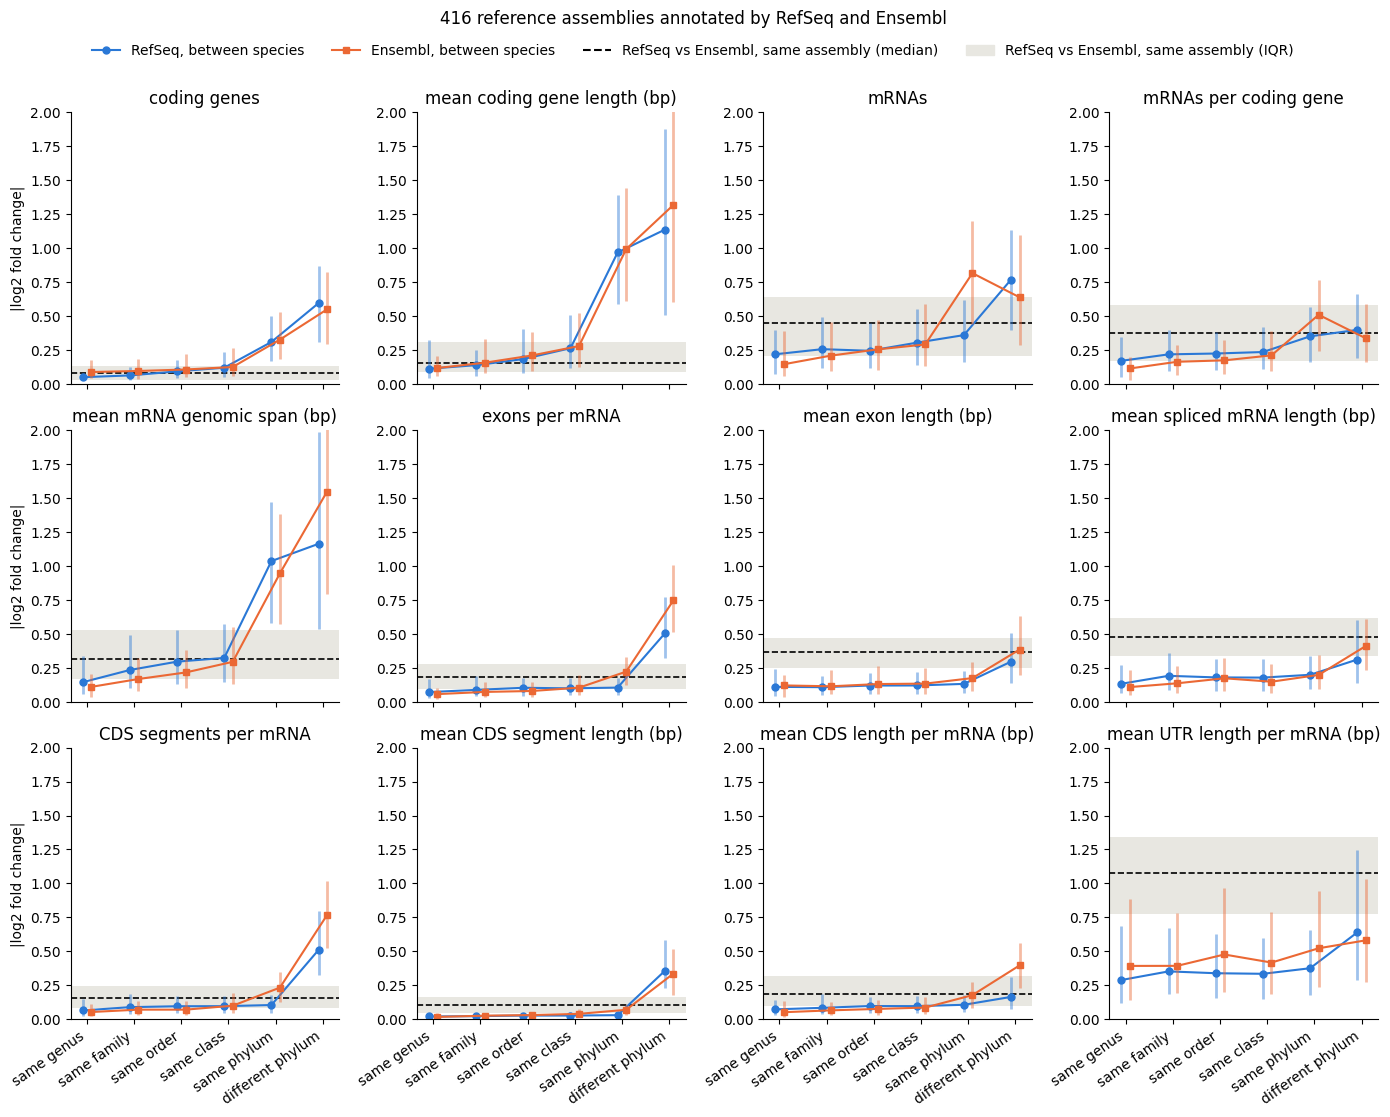

In [20]:
# Figure 1: same-pipeline distance between species (median, IQR) by relationship vs same-assembly pipeline effect
COLORS = {"RefSeq": "#2a78d6", "Ensembl": "#eb6834"}
rels = [r for r in RELATIONSHIPS if r in set(summary.relationship)]
x = np.arange(len(rels))
NCOL = 4
nrow = -(-len(PANEL) // NCOL)
fig, axes = plt.subplots(nrow, NCOL, figsize=(14, 3.6 * nrow), sharex=True, squeeze=False)
axes = axes.ravel()
for ax in axes[len(PANEL):]:
    ax.set_visible(False)
for ax, m in zip(axes, PANEL):
    e = genomes[f"pipeline_log2fc_{m}"].abs()
    ax.axhspan(e.quantile(0.25), e.quantile(0.75), color="#e8e7e1", lw=0, zorder=0)
    ax.axhline(e.median(), color="k", lw=1.2, ls="--", zorder=1)
    for k, p in enumerate(PIPELINES):
        s = summary[(summary.metric == m) & (summary.pipeline == p)].set_index("relationship").reindex(rels)
        xs = x + (k - 0.5) * 0.18
        ax.vlines(xs, s.q25, s.q75, color=COLORS[p], lw=2, alpha=0.45)
        ax.plot(xs, s.median_abs_log2fc, color=COLORS[p], marker="os"[k], ms=5, lw=1.5, label=f"{p}, between species")
    ax.set_title(LABEL[m])
    ax.set_xticks(x, rels, rotation=35, ha="right")
    ax.set_ylim(bottom=0, top=2)
    ax.spines[["top", "right"]].set_visible(False)
for ax in axes[::NCOL]:
    ax.set_ylabel("|log2 fold change|")
handles = axes[0].get_legend_handles_labels()[0] + [
    plt.Line2D([], [], color="k", ls="--", label="RefSeq vs Ensembl, same assembly (median)"),
    plt.Rectangle((0, 0), 1, 1, color="#e8e7e1", label="RefSeq vs Ensembl, same assembly (IQR)")]
fig.legend(handles=handles, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.0 + 0.03 / nrow), frameon=False)
fig.suptitle(f"{n} reference assemblies annotated by RefSeq and Ensembl", y=1.0 + 0.09 / nrow)
fig.tight_layout()
fig.savefig("figures/distances.png", dpi=200, bbox_inches="tight")
plt.show()


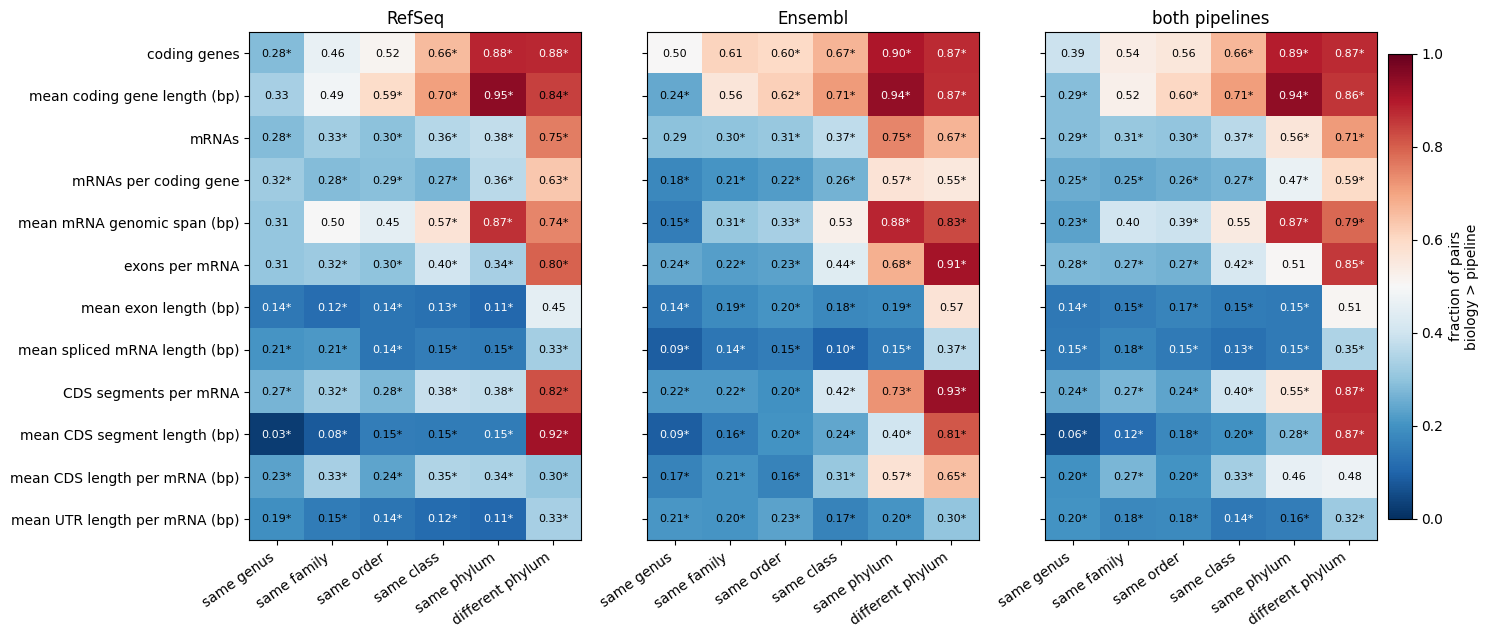

In [21]:
# Figure 2: fraction of assembly pairs where biology > pipeline (* = 95 % CI excludes 0.5)
fig, axes = plt.subplots(1, 3, figsize=(15, 0.45 * len(PANEL) + 1.2), sharey=True)
for ax, p in zip(axes, PIPELINES + ["both"]):
    s = summary[summary.pipeline == p]
    frac = s.pivot(index="metric", columns="relationship", values="frac_biology").reindex(index=PANEL, columns=rels)
    sig = (s.assign(sig=(s.ci_low > 0.5) | (s.ci_high < 0.5))
           .pivot(index="metric", columns="relationship", values="sig").reindex(index=PANEL, columns=rels))
    im = ax.imshow(frac.values, cmap="RdBu_r", vmin=0, vmax=1, aspect="auto")
    for a in range(frac.shape[0]):
        for b in range(frac.shape[1]):
            v = frac.values[a, b]
            if np.isfinite(v):
                ax.text(b, a, f"{v:.2f}{'*' if sig.values[a, b] else ''}", ha="center", va="center", fontsize=8,
                        color="w" if abs(v - 0.5) > 0.35 else "k")
    ax.set_xticks(range(len(rels)), rels, rotation=35, ha="right")
    ax.set_yticks(range(len(PANEL)), [LABEL[m] for m in PANEL])
    ax.set_title({"both": "both pipelines"}.get(p, p))
cbar = fig.colorbar(im, ax=axes, fraction=0.02, pad=0.01)
cbar.set_label("fraction of pairs\nbiology > pipeline")
fig.savefig("figures/frac_biology.png", dpi=200, bbox_inches="tight")
plt.show()


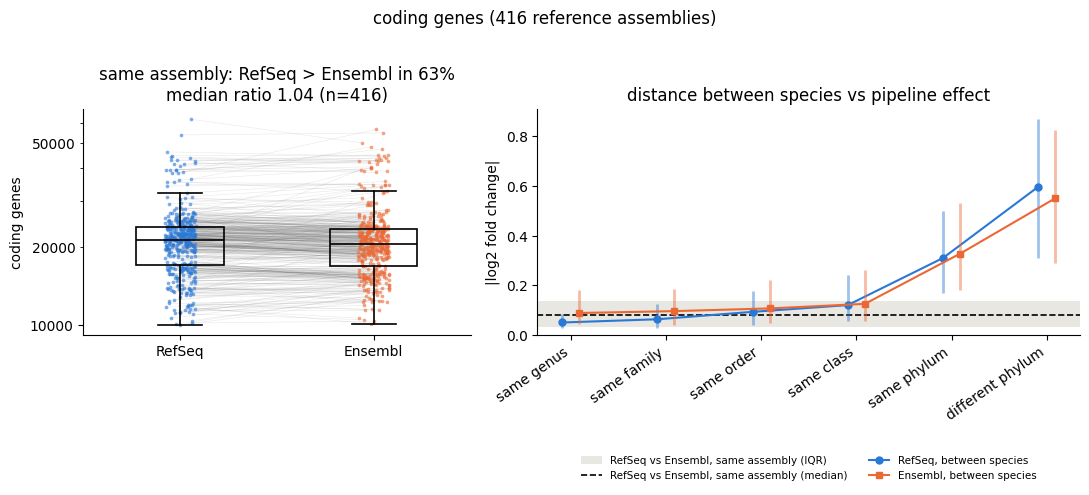

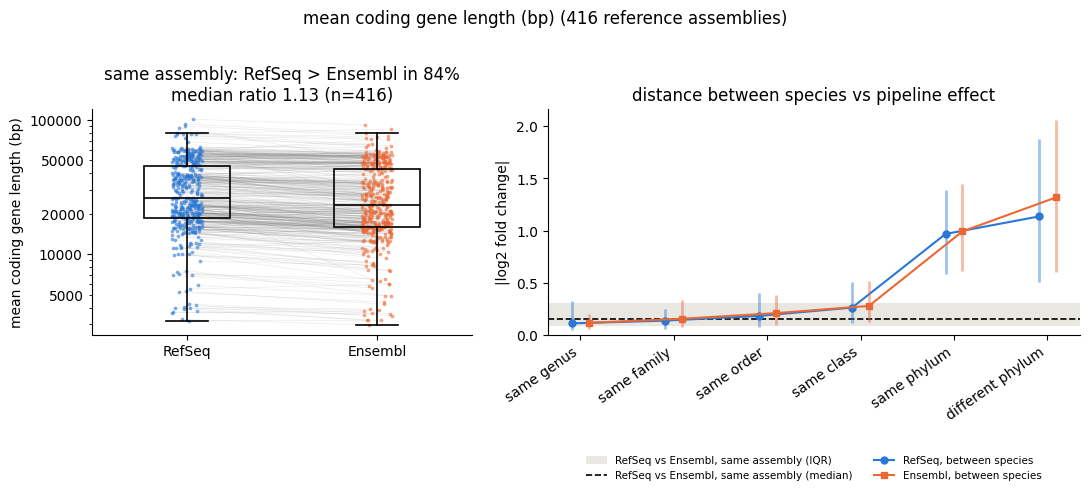

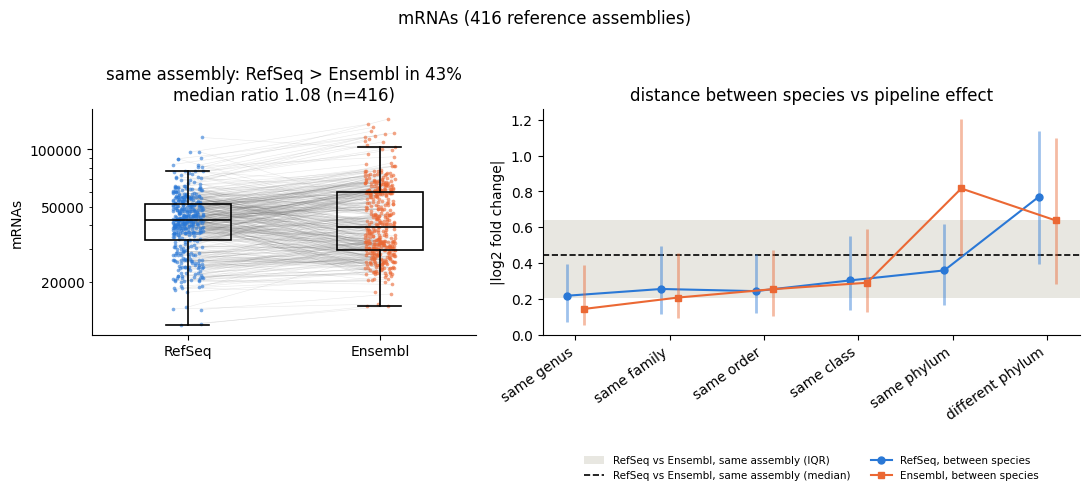

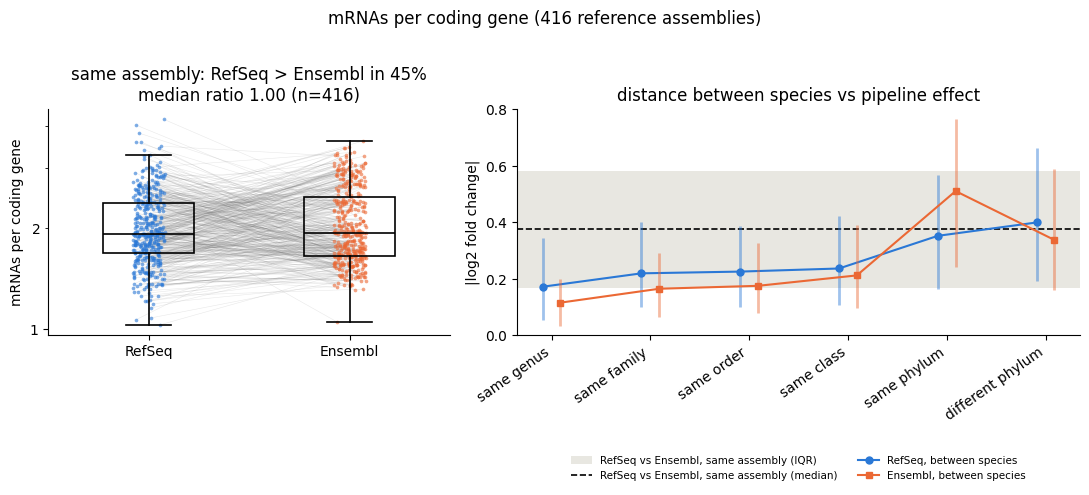

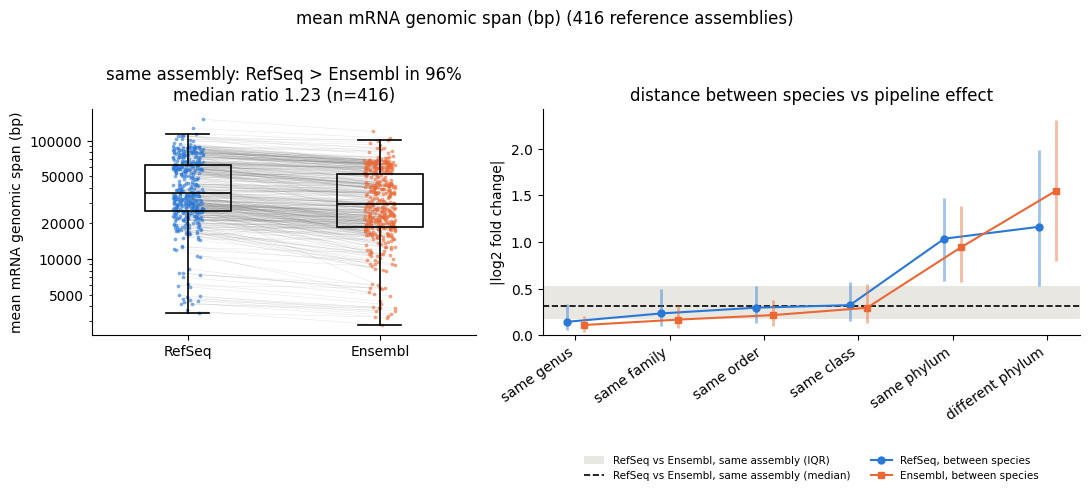

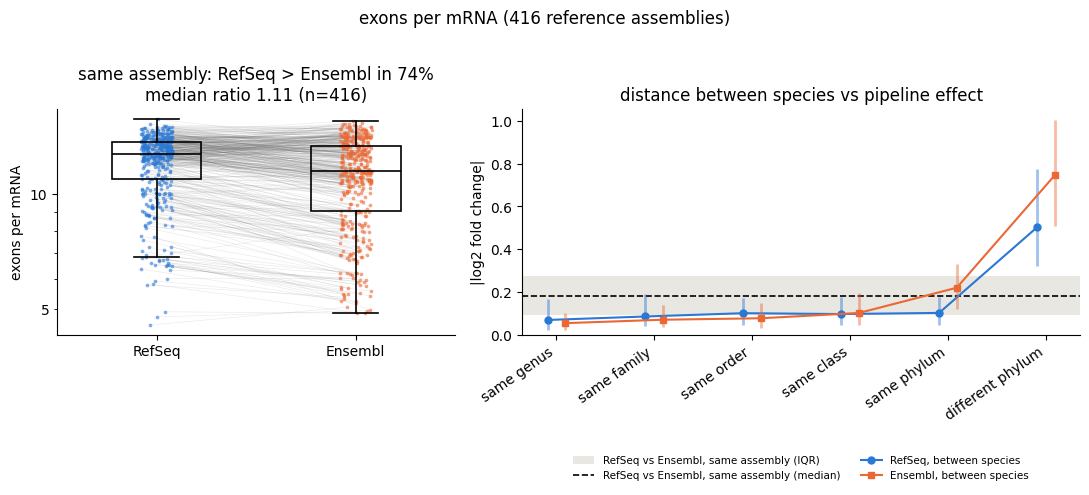

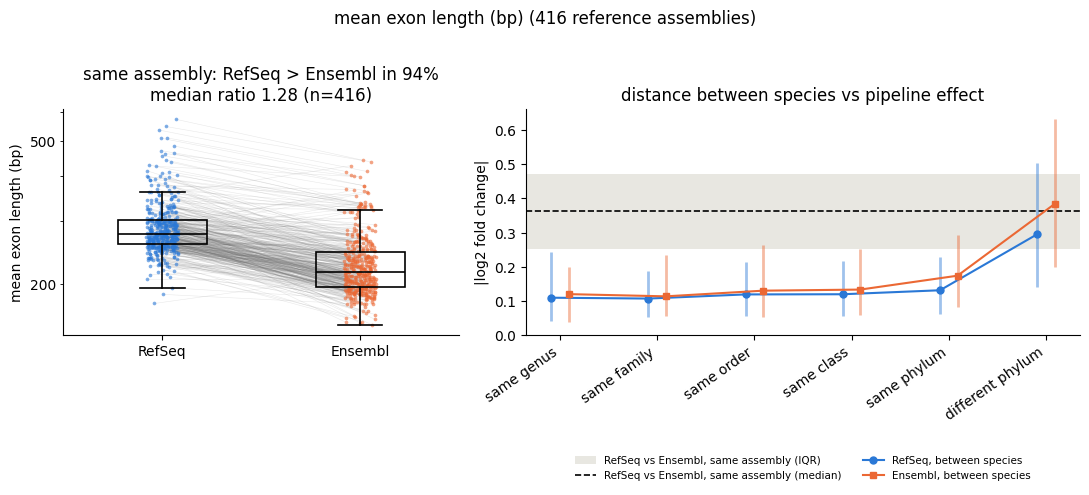

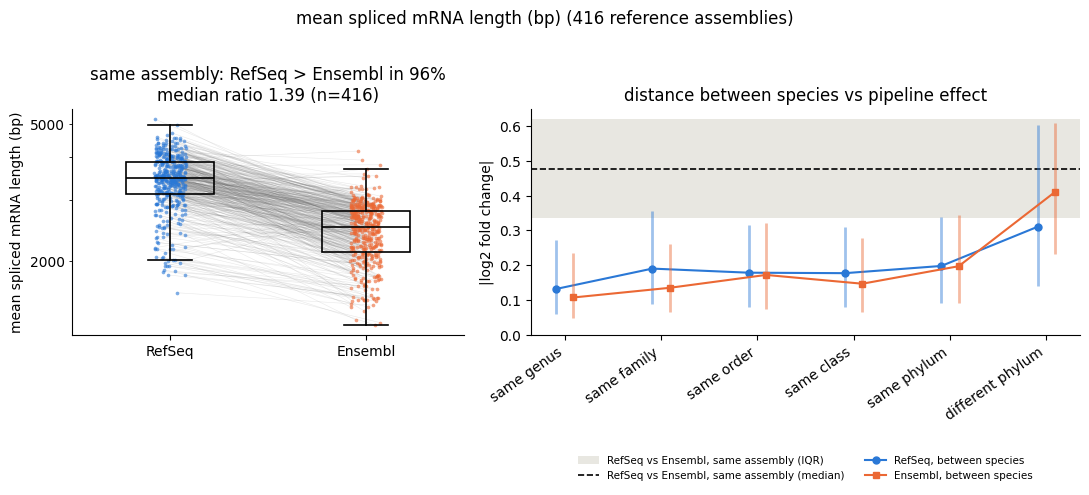

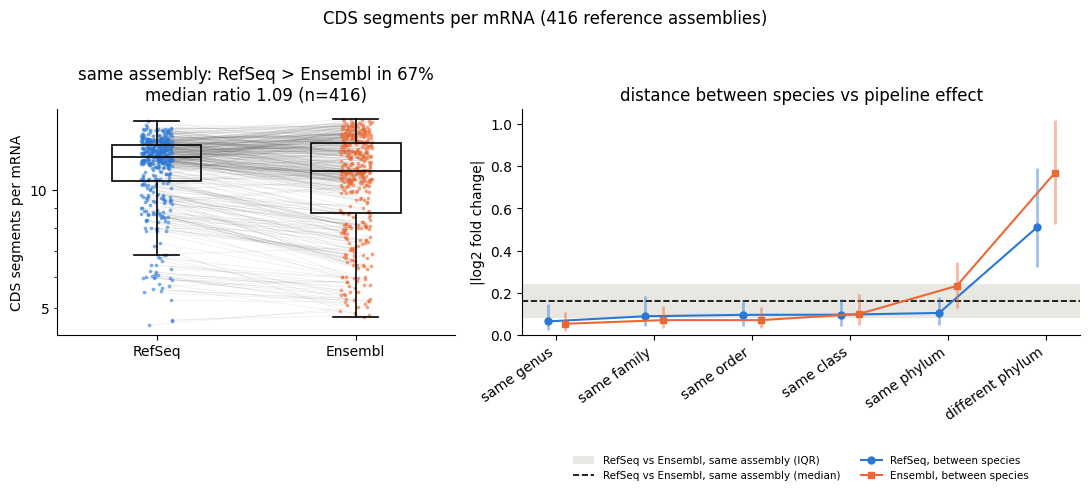

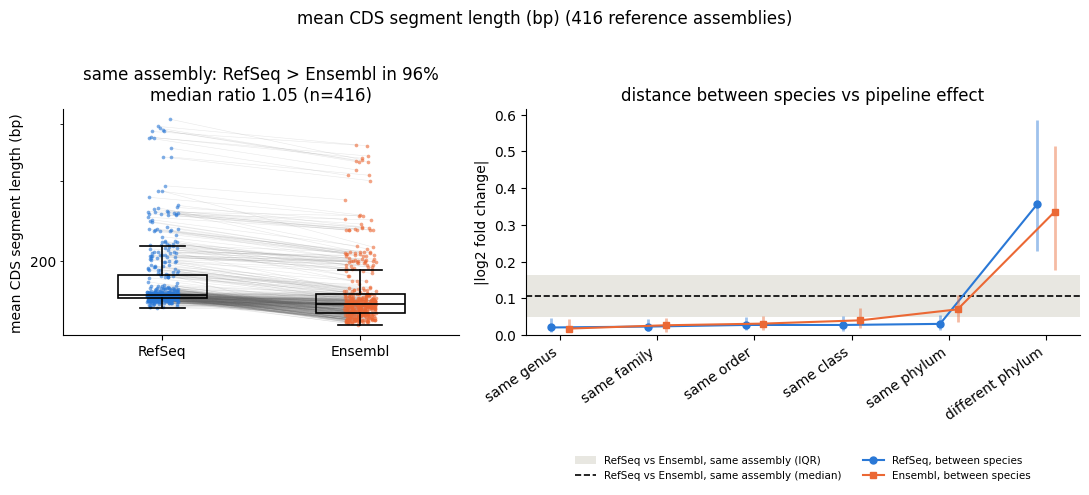

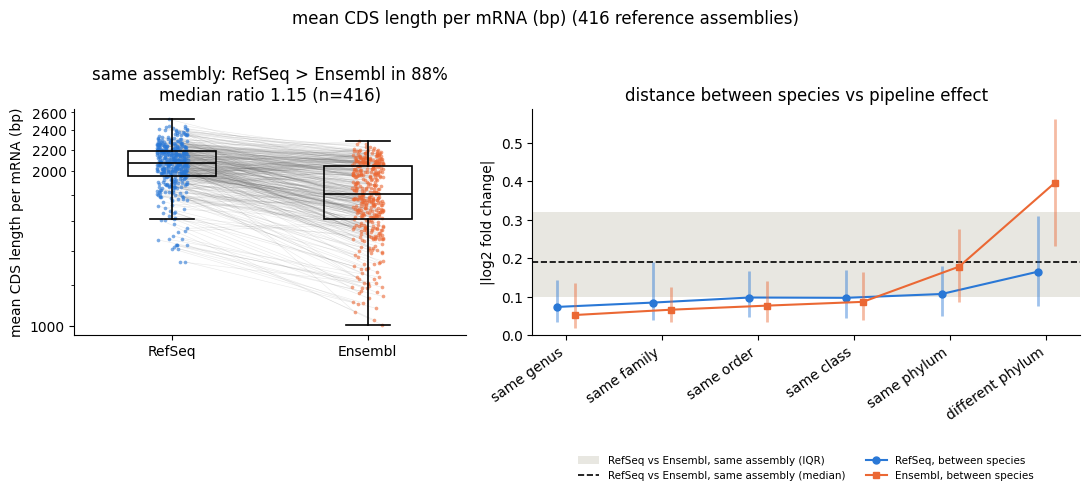

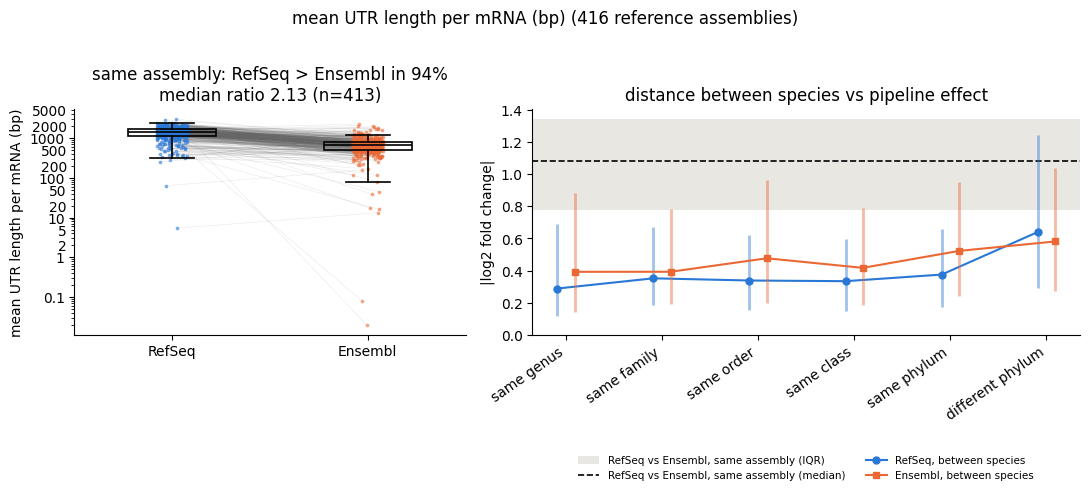

In [10]:
# Figure 3: one figure per metric, two panels:
#   (left)  RefSeq vs Ensembl values: boxplot, one dot per annotation, a transparent line joins the two
#           annotations of the same assembly
#   (right) |log2FC| between species by relationship (median, IQR) vs the same-assembly pipeline effect
import matplotlib.ticker as mticker
PLAIN = mticker.FuncFormatter(lambda v, _: f"{v:g}")
PLAIN_MINOR = mticker.FuncFormatter(lambda v, _: f"{v:g}" if f"{v:g}"[0] in "25" else "")
os.makedirs("figures/per_metric", exist_ok=True)
rng_jit = np.random.default_rng(0)
pos = np.arange(1, len(PIPELINES) + 1)
for m in PANEL:
    fig, (ax_b, ax_d) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.4]})

    # (left) paired boxplot
    d = genomes[[f"{p}_{m}" for p in PIPELINES]].dropna()
    xs = pos + rng_jit.uniform(-0.08, 0.08, size=(len(d), len(PIPELINES)))
    ax_b.plot(xs.T, d.values.T, color="0.4", lw=0.4, alpha=0.15, zorder=1)
    for k, p in enumerate(PIPELINES):
        ax_b.scatter(xs[:, k], d[f"{p}_{m}"], s=7, color=COLORS[p], alpha=0.6, lw=0, zorder=2)
    bp = ax_b.boxplot([d[f"{p}_{m}"] for p in PIPELINES], positions=pos, widths=0.45, patch_artist=True,
                      showfliers=False, zorder=3)
    for patch in bp["boxes"]:
        patch.set(facecolor="none", edgecolor="k", lw=1.2)
    for part in ("whiskers", "caps", "medians"):
        for line in bp[part]:
            line.set(color="k", lw=1.2)
    up = (d[f"RefSeq_{m}"] > d[f"Ensembl_{m}"]).mean()
    ratio = d[f"RefSeq_{m}"].median() / d[f"Ensembl_{m}"].median()
    ax_b.set_xticks(pos, PIPELINES)
    ax_b.set_yscale("log")
    ax_b.yaxis.set_major_formatter(PLAIN)
    ax_b.yaxis.set_minor_formatter(PLAIN_MINOR)
    ax_b.set_ylabel(LABEL[m])
    ax_b.set_title(f"same assembly: RefSeq > Ensembl in {up:.0%}\nmedian ratio {ratio:.2f} (n={len(d)})")

    # (right) distances
    e = genomes[f"pipeline_log2fc_{m}"].abs()
    ax_d.axhspan(e.quantile(0.25), e.quantile(0.75), color="#e8e7e1", lw=0, zorder=0,
                 label="RefSeq vs Ensembl, same assembly (IQR)")
    ax_d.axhline(e.median(), color="k", lw=1.2, ls="--", zorder=1, label="RefSeq vs Ensembl, same assembly (median)")
    for k, p in enumerate(PIPELINES):
        s = summary[(summary.metric == m) & (summary.pipeline == p)].set_index("relationship").reindex(rels)
        xr = x + (k - 0.5) * 0.18
        ax_d.vlines(xr, s.q25, s.q75, color=COLORS[p], lw=2, alpha=0.45)
        ax_d.plot(xr, s.median_abs_log2fc, color=COLORS[p], marker="os"[k], ms=5, lw=1.5, label=f"{p}, between species")
    ax_d.set_xticks(x, rels, rotation=35, ha="right")
    ax_d.set_ylim(bottom=0)
    ax_d.set_ylabel("|log2 fold change|")
    ax_d.set_title("distance between species vs pipeline effect")

    for ax in (ax_b, ax_d):
        ax.spines[["top", "right"]].set_visible(False)
    fig.suptitle(f"{LABEL[m]} ({n} reference assemblies)", y=1.02)
    fig.tight_layout()
    # legend below the right panel, placed after layout so it never overlaps the tick labels
    box = ax_d.get_position()
    fig.legend(*ax_d.get_legend_handles_labels(), fontsize=7.5, frameon=False, ncol=2, loc="upper center",
               bbox_to_anchor=((box.x0 + box.x1) / 2, -0.02))
    fig.savefig(f"figures/per_metric/{m}.png", dpi=200, bbox_inches="tight")
    plt.show()
